<a href="https://colab.research.google.com/github/mohithkumarreddyputtur-sketch/DEEP-LEARINING-/blob/main/Experiment_16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

SimpleRNN MAE 0.22031575166267015 RMSE 0.27776733135446213
LSTM MAE 0.836862735363617 RMSE 1.0019343556605407


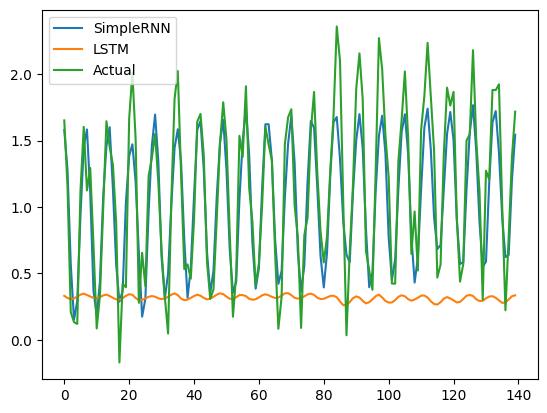

In [1]:
import tensorflow as tf, numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error,mean_squared_error
rng=np.random.default_rng(16); s=100+np.arange(730)*.05+10*np.sin(np.arange(730)*2*np.pi/7)+rng.normal(0,3,730)
X=np.array([s[i:i+30] for i in range(len(s)-30)]); y=s[30:]; X=(X-X.mean())/X.std(); y=(y-y.mean())/y.std(); X=X[...,None]
split=int(len(X)*.8); Xt,Xv=X[:split],X[split:]; yt,yv=y[:split],y[split:]
for layer in [tf.keras.layers.SimpleRNN(32),tf.keras.layers.LSTM(32)]:
 m=tf.keras.Sequential([tf.keras.layers.Input((30,1)),layer,tf.keras.layers.Dense(1)]); m.compile('adam','mse'); h=m.fit(Xt,yt,validation_split=.2,epochs=10,verbose=0); p=m.predict(Xv,verbose=0).ravel()
 print(layer.__class__.__name__,'MAE',mean_absolute_error(yv,p),'RMSE',mean_squared_error(yv,p)**.5)
 plt.plot(p,label=layer.__class__.__name__)
plt.plot(yv,label='Actual'); plt.legend(); plt.show()